In [4]:
#Dataset: Titanic - Machine Learning from Disaster
#Source: Kaggle Titanic dataset
#File: train.csv

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("train.csv")

In [7]:
df.head()
df.shape

(891, 12)

In [8]:
class_summary = df.groupby("Pclass").agg(
    Passenger_Count=("PassengerId", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Fare=("Fare", "mean"),
    Median_Fare=("Fare", "median"),
    Survival_Rate=("Survived", "mean")
)

class_summary

,Passenger_Count,Mean_Age,Mean_Fare,Median_Fare,Survival_Rate
Pclass,,,,,
1,216,38.233441,84.154687,60.2875,0.629630
2,184,29.877630,20.662183,14.2500,0.472826
3,491,25.140620,13.675550,8.0500,0.242363


In [9]:
class_summary["Survival_Rate_Percent"] = (
    class_summary["Survival_Rate"] * 100
).round(2)

class_summary

,Passenger_Count,Mean_Age,Mean_Fare,Median_Fare,Survival_Rate,Survival_Rate_Percent
Pclass,,,,,,
1,216,38.233441,84.154687,60.2875,0.629630,62.96
2,184,29.877630,20.662183,14.2500,0.472826,47.28
3,491,25.140620,13.675550,8.0500,0.242363,24.24


In [10]:
sex_class_summary = df.groupby(["Sex", "Pclass"]).agg(
    Passenger_Count=("PassengerId", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Fare=("Fare", "mean"),
    Survival_Rate=("Survived", "mean")
)

sex_class_summary.round(2)

Passenger_Count  Mean_Age  Mean_Fare  Survival_Rate
Sex    Pclass                                                     
female 1                    94     34.61     106.13           0.97
       2                    76     28.72      21.97           0.92
       3                   144     21.75      16.12           0.50
male   1                   122     41.28      67.23           0.37
       2                   108     30.74      19.74           0.16
       3                   347     26.51      12.66           0.14

In [11]:
class_info = pd.DataFrame({
    "Pclass": [1, 2],
    "Class_Name": ["First Class", "Second Class"],
    "Service_Level": ["Premium", "Standard"]
})

class_info

,Pclass,Class_Name,Service_Level
0,1,First Class,Premium
1,2,Second Class,Standard


In [12]:
inner_join = pd.merge(
    df,
    class_info,
    on="Pclass",
    how="inner"
)

inner_join.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Class_Name,Service_Level
0,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,First Class,Premium
1,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,First Class,Premium
2,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,First Class,Premium
3,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,Second Class,Standard
4,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,First Class,Premium


In [13]:
inner_join.shape

(400, 14)

In [14]:
left_join = pd.merge(
    df,
    class_info,
    on="Pclass",
    how="left"
)

left_join.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Class_Name,Service_Level
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,NaN,NaN
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,First Class,Premium
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,NaN,NaN
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,First Class,Premium
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,NaN,NaN


In [15]:
left_join.shape

(891, 14)

In [16]:
right_join = pd.merge(
    df,
    class_info,
    on="Pclass",
    how="right"
)
right_join.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Class_Name,Service_Level
0,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,First Class,Premium
1,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,First Class,Premium
2,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,First Class,Premium
3,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,First Class,Premium
4,24,1,1,"Sloper, Mr. William Thompson",male,28.0,0,0,113788,35.5000,A6,S,First Class,Premium


In [17]:
fare_pivot = pd.pivot_table(
    df,
    values="Fare",
    index="Sex",
    columns="Pclass",
    aggfunc="mean"
)

fare_pivot.round(2)

Pclass,1,2,3
Sex,,,
female,106.13,21.97,16.12
male,67.23,19.74,12.66


In [18]:
wide_data = df.loc[
    0:9,
    ["PassengerId", "Age", "Fare"]
]

wide_data

,PassengerId,Age,Fare
0,1,22.0,7.2500
1,2,38.0,71.2833
2,3,26.0,7.9250
3,4,35.0,53.1000
4,5,35.0,8.0500
5,6,NaN,8.4583
6,7,54.0,51.8625
7,8,2.0,21.0750
8,9,27.0,11.1333
9,10,14.0,30.0708


In [19]:
long_data = wide_data.melt(
    id_vars="PassengerId",
    value_vars=["Age", "Fare"],
    var_name="Variable",
    value_name="Value"
)

long_data

,PassengerId,Variable,Value
0,1,Age,22.0000
1,2,Age,38.0000
2,3,Age,26.0000
3,4,Age,35.0000
4,5,Age,35.0000
5,6,Age,NaN
6,7,Age,54.0000
7,8,Age,2.0000
8,9,Age,27.0000
9,10,Age,14.0000


In [20]:
wide_data.shape

(10, 3)

In [21]:
long_data.shape

(20, 3)

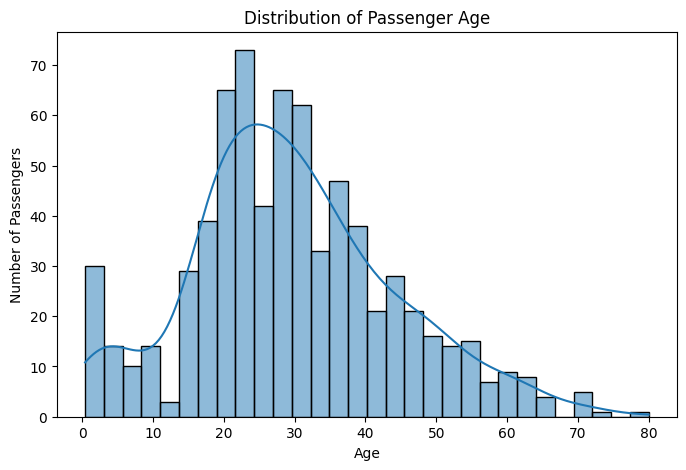

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

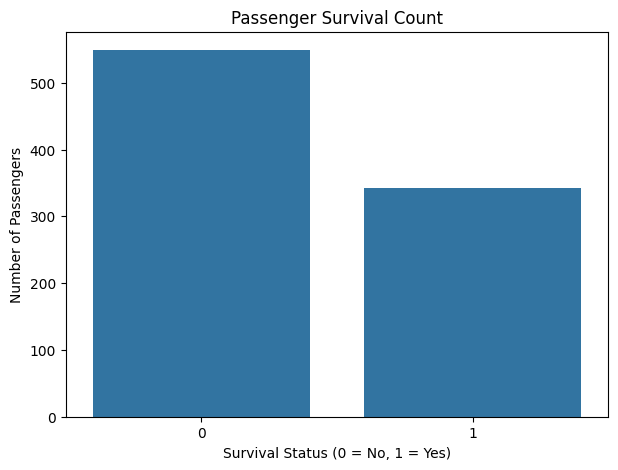

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Survived"
)

plt.title("Passenger Survival Count")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

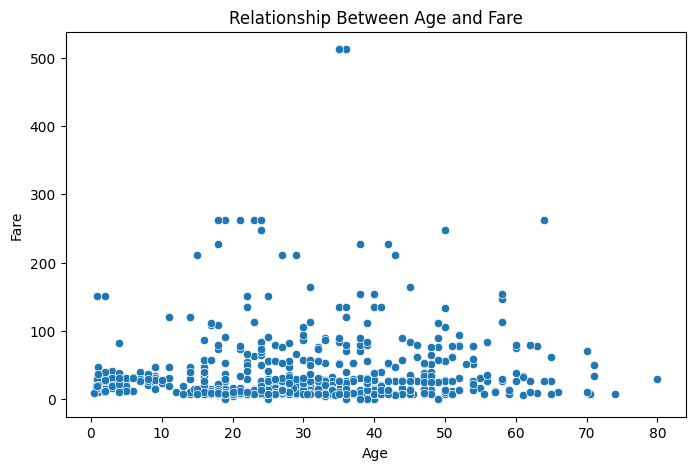

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare"
)

plt.title("Relationship Between Age and Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

In [25]:
age_fare_correlation = df["Age"].corr(df["Fare"])

age_fare_correlation

np.float64(0.0960666917690389)

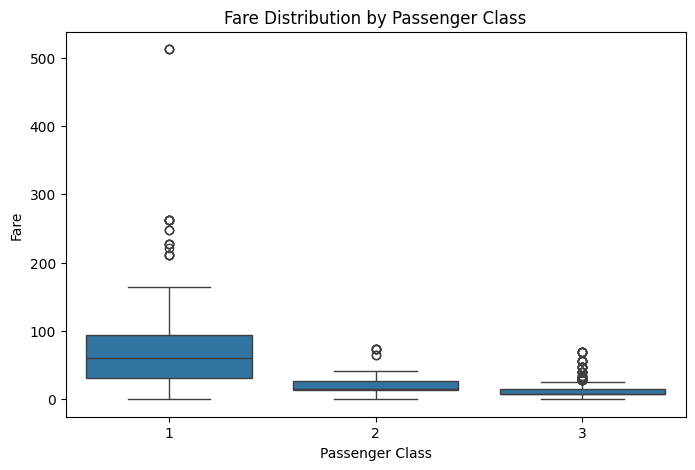

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Pclass",
    y="Fare"
)

plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")

plt.show()

In [27]:
df[["Age", "Fare"]].describe()

,Age,Fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


In [28]:
df["Age"].corr(df["Fare"])

np.float64(0.0960666917690389)